In [121]:
import xcs_code_stockpile as xcs
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

In [122]:
def slow_mean(stack, valid):
    n = 0
    out = np.zeros(stack.shape[1:])
    for i in tqdm(list(range(stack.shape[0]))):
        if valid[i]:
            out += stack[i, ...]
            n += 1
    return out / n

In [123]:
proposal_number = 101927227  # noqa

In [124]:
h5_epix = xcs.load_smalldata(90, proposal_number)
h5dict_epix = xcs.H5Dictionary(
    stack='/jungfrau1M/ROI_area',
    i0=lambda h5: h5['diodeGon/channels'][..., 0],
    laser_on='evr/code_41',
    delay='scan/awg_delay_ns_delay',
    measured_voltage='ai/ch04'
)
stack_jf = h5_jf[h5dict_jf.stack]
h5_epix = xcs.load_smalldata(100, proposal_number)
h5dict_epix = xcs.H5Dictionary(
    stack='epix_6/ROI_area',
    i0=lambda h5: h5['diodeGon/channels'][..., 0],
    laser_on='evr/code_41',
    delay='scan/awg_delay_ns_delay',
    measured_voltage='ai/ch04'
)
stack_epix = h5_epix[h5dict_epix.stack]

In [170]:
roi_jf = (slice(55, 85), slice(162, 198))
roi_jf_full = (slice(None), slice(None))

In [171]:
voltage_high_epix = h5_epix[h5dict_epix.measured_voltage][...] > 1.0
laser_on_epix = h5_epix[h5dict_epix.laser_on][...].astype(bool)
n_on_epix = np.count_nonzero(voltage_high_epix)
n_off_epix = np.count_nonzero((~voltage_high_epix) & (~laser_on_epix))
high_and_on_epix = (voltage_high_epix) & (laser_on_epix)
off_epix = (~voltage_high_epix) & (~laser_on_epix)

In [172]:
voltage_high_jf = h5_jf[h5dict_jf.measured_voltage][...] > 1.0
laser_on_jf = h5_jf[h5dict_jf.laser_on][...].astype(bool)
n_on_jf = np.count_nonzero(voltage_high_jf)
n_off_jf = np.count_nonzero((~voltage_high_jf) & (~laser_on_jf))
high_and_on_jf = (voltage_high_jf) & (laser_on_jf)
off_jf = (~voltage_high_jf) & (~laser_on_jf)

In [173]:
mean_on_jf = np.flip(slow_mean(stack_jf, high_and_on_jf)[*roi_jf], axis=0)
mean_off_jf = np.flip(slow_mean(stack_jf, off_jf)[*roi_jf], axis=0)

100%|██████████| 20577/20577 [00:00<00:00, 31453.76it/s]


In [129]:
mean_on_epix = slow_mean(stack_epix, high_and_on_epix)
mean_off_epix = slow_mean(stack_epix, off_epix)

100%|██████████| 24543/24543 [00:07<00:00, 3121.66it/s]


In [174]:
diff_jf = mean_on_jf / mean_off_jf - 1.0
diff_epix = mean_on_epix / mean_off_epix - 1.0

/lscratch/bfichera/tmp/ipykernel_3743737/3227375113.py:2: RuntimeWarning: invalid value encountered in divide
  diff_epix = mean_on_epix / mean_off_epix - 1.0


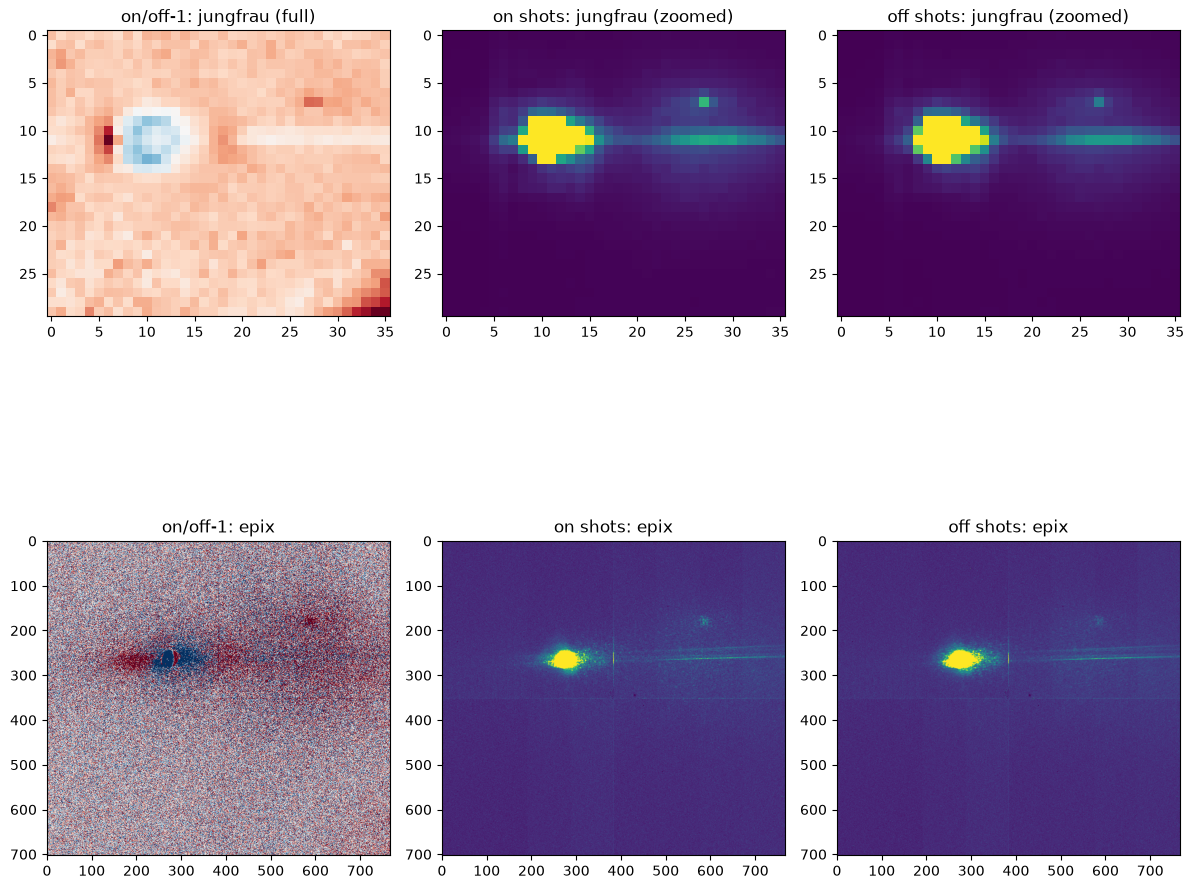

In [175]:
fig, axd = plt.subplot_mosaic([['diff_jf', 'on_jf', 'off_jf'], ['diff_epix', 'on_epix', 'off_epix']], figsize=(12, 12))
axd['diff_jf'].imshow(diff_jf, cmap='RdBu_r', vmin=-1.0, vmax=1.0)
axd['on_jf'].imshow(mean_on_jf, vmin=0.0, vmax=200.0)
axd['off_jf'].imshow(mean_off_jf, vmin=0.0, vmax=200.0)
axd['diff_epix'].imshow(diff_epix, cmap='RdBu_r', vmin=-0.1, vmax=0.1)
axd['on_epix'].imshow(mean_on_epix, vmin=0.0, vmax=0.5)
axd['off_epix'].imshow(mean_off_epix, vmin=0.0, vmax=0.5)

axd['diff_jf'].set_title('on/off-1: jungfrau (zoomed)')
axd['on_jf'].set_title('on shots: jungfrau (zoomed)')
axd['off_jf'].set_title('off shots: jungfrau (zoomed)')
axd['diff_epix'].set_title('on/off-1: epix')
axd['on_epix'].set_title('on shots: epix')
axd['off_epix'].set_title('off shots: epix')

fig.tight_layout()

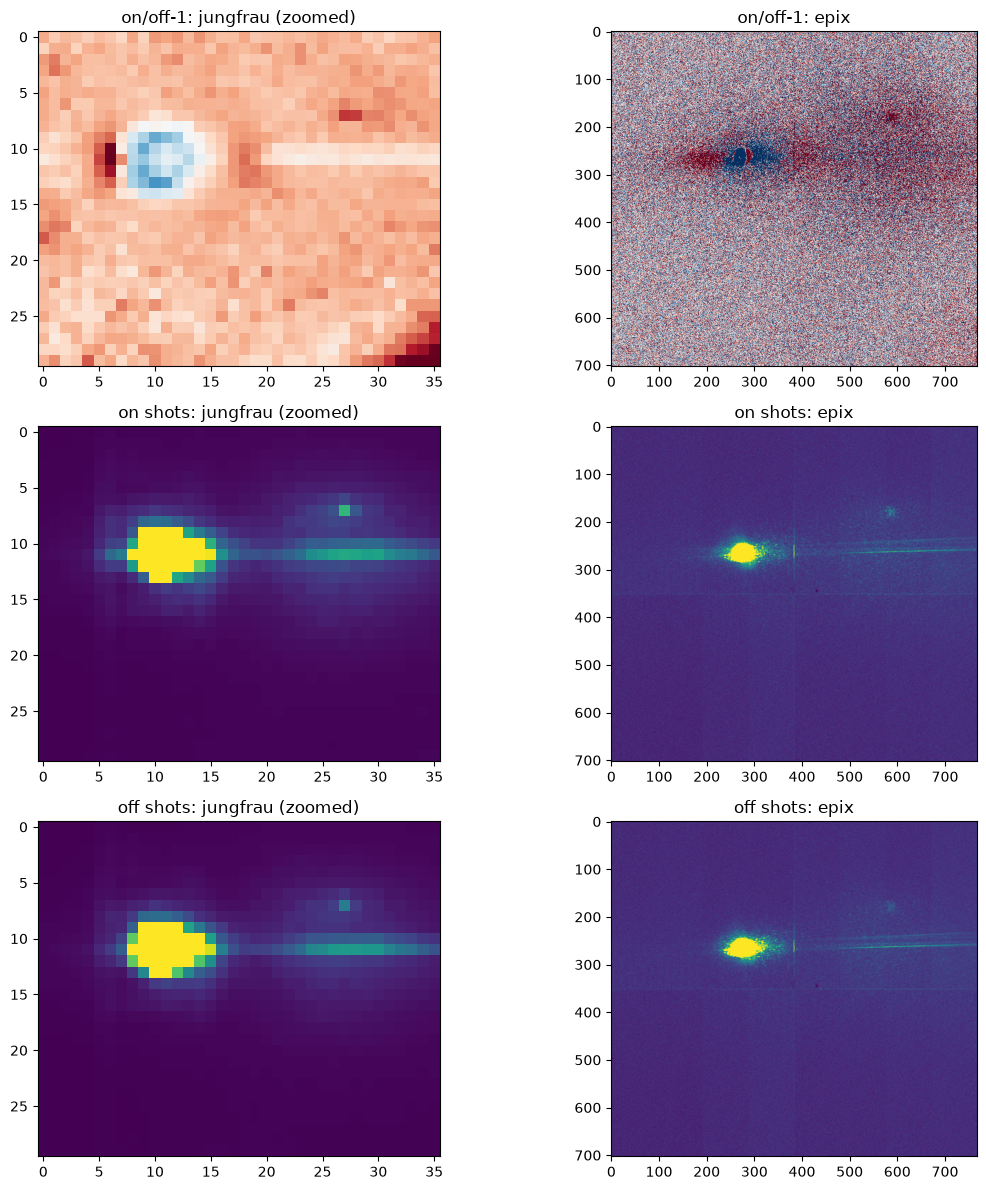

In [190]:
fig, axd = plt.subplot_mosaic([['diff_jf', 'diff_epix'], ['on_jf', 'on_epix'], ['off_jf', 'off_epix']], figsize=(12, 12))
axd['diff_jf'].imshow(diff_jf, cmap='RdBu_r', vmin=-0.8, vmax=0.8)
axd['on_jf'].imshow(mean_on_jf, vmin=0.0, vmax=200.0)
axd['off_jf'].imshow(mean_off_jf, vmin=0.0, vmax=200.0)
axd['diff_epix'].imshow(diff_epix, cmap='RdBu_r', vmin=-0.1, vmax=0.1)
axd['on_epix'].imshow(mean_on_epix, vmin=0.0, vmax=0.5)
axd['off_epix'].imshow(mean_off_epix, vmin=0.0, vmax=0.5)

axd['diff_jf'].set_title('on/off-1: jungfrau (zoomed)')
axd['on_jf'].set_title('on shots: jungfrau (zoomed)')
axd['off_jf'].set_title('off shots: jungfrau (zoomed)')
axd['diff_epix'].set_title('on/off-1: epix')
axd['on_epix'].set_title('on shots: epix')
axd['off_epix'].set_title('off shots: epix')

fig.tight_layout()

In [184]:
mean_on_jf_full = slow_mean(stack_jf, high_and_on_jf)[*roi_jf_full]
mean_off_jf_full = slow_mean(stack_jf, off_jf)[*roi_jf_full]

100%|██████████| 20577/20577 [00:00<00:00, 30880.79it/s]


/lscratch/bfichera/tmp/ipykernel_3743737/4284862434.py:2: RuntimeWarning: invalid value encountered in divide
  axs[0].imshow((mean_on_jf_full / mean_off_jf_full - 1.0), vmin=-1.0, vmax=1.0, cmap='RdBu_r')


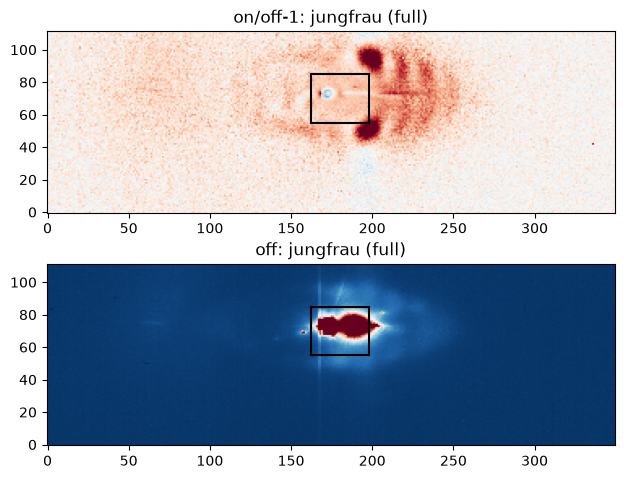

In [196]:
fig, axs = plt.subplots(2, 1)
axs[0].imshow((mean_on_jf_full / mean_off_jf_full - 1.0), vmin=-1.0, vmax=1.0, cmap='RdBu_r')
axs[1].imshow(mean_off_jf_full, vmin=0.0, vmax=10.0, cmap='RdBu_r')
for ax in axs:
    ax.plot([roi_jf[1].start, roi_jf[1].stop], [roi_jf[0].start, roi_jf[0].start], color='black')
    ax.plot([roi_jf[1].start, roi_jf[1].stop], [roi_jf[0].stop, roi_jf[0].stop], color='black')
    ax.plot([roi_jf[1].stop, roi_jf[1].stop], [roi_jf[0].start, roi_jf[0].stop], color='black')
    ax.plot([roi_jf[1].start, roi_jf[1].start], [roi_jf[0].start, roi_jf[0].stop], color='black')
    ax.invert_yaxis()
axs[0].set_title('on/off-1: jungfrau (full)')
axs[1].set_title('off: jungfrau (full)')
fig.tight_layout()
plt.show()
